# Tiny GPT from Scratch

Build and train a small GPT-style language model, the same design as Llama, Qwen and ChatGPT but tiny, on the complete plays of Shakespeare, until it writes fake Shakespeare.

| Step | What you learn |
|---|---|
| 1. Counting | What a language model is, how it writes text, and what **loss** means |
| 2. Bigram neural network | The **training loop** every neural network uses |
| 3. Tiny GPT | **Attention** and the Transformer, the ideas behind every modern AI model |
| 4. Experiments | Model size, **overfitting**, context length and temperature |

## How to use this notebook
1. **Turn on the free GPU first:** menu **Runtime → Change runtime type → T4 GPU → Save**.
2. Run each grey code box in order: click it and press **Shift + Enter** (or click ▶ on its left). Its output appears underneath.
3. Read the text boxes between them, which explain what's happening.

**Note:** Colab deletes everything when you close it or leave it idle for too long. The last section shows how to download your results.

In [1]:
# Check the GPU is switched on
import torch
if torch.cuda.is_available():
    print("GPU ready:", torch.cuda.get_device_name(0))
else:
    print("No GPU! Go to Runtime -> Change runtime type -> T4 GPU, then run this box again.")

GPU ready: Tesla T4


## Setup: get the text and turn it into numbers

The text is "Tiny Shakespeare": about 1 million characters of Shakespeare's plays (out of copyright).

Models can't read letters, only numbers, so each character gets an ID number: this is called **tokenising**. We use one token per character to keep things simple. Real models like Llama use tokens that are whole words or chunks of words.

We also **split** the text: the first 90% for training, the last 10% for **validation**. The model never trains on the validation text, so its loss there tells us how well it handles text it hasn't seen.

In [2]:
import urllib.request, os

URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
if not os.path.exists("input.txt"):
    urllib.request.urlretrieve(URL, "input.txt")
text = open("input.txt", encoding="utf-8").read()

chars = sorted(set(text))            # every distinct character
vocab_size = len(chars)
to_id = {c: i for i, c in enumerate(chars)}
to_char = {i: c for i, c in enumerate(chars)}
encode = lambda s: [to_id[c] for c in s]
decode = lambda ids: "".join(to_char[i] for i in ids)

data = encode(text)
n = int(len(data) * 0.9)
train_list, val_list = data[:n], data[n:]

print(f"Text length: {len(text):,} characters")
print(f"Vocabulary: {vocab_size} characters: {''.join(chars)!r}")
print("\nThe first 300 characters:\n")
print(text[:300])

Text length: 1,115,394 characters
Vocabulary: 65 characters: "\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"

The first 300 characters:

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


## Step 1: The simplest language model, built by counting

A language model does one job: **given some text, predict the next character.**

This one only looks at the *last* character. It counts how often each character follows each other one across the training text. That's called a **bigram** model. No AI library is needed for this, just counting.

Every count starts at 1 rather than 0. This is called **smoothing**: without it, a pair never seen in training (like "zx") would get probability 0, and the loss below would become infinite.

In [3]:
import math, random

V = vocab_size
counts = [[1] * V for _ in range(V)]          # counts[a][b] = times b came after a
for a, b in zip(train_list, train_list[1:]):
    counts[a][b] += 1
probs = [[c / sum(row) for c in row] for row in counts]   # each row adds up to 1

print("Most likely next characters:")
for ch in ["q", "t", "h", " ", "\n"]:
    row = probs[to_id[ch]]
    top = sorted(range(V), key=lambda i: row[i], reverse=True)[:3]
    print(f"  after {ch!r}: " + ", ".join(f"{to_char[i]!r} {row[i]:.0%}" for i in top))

# Write text: repeatedly pick a next character using the probabilities
random.seed(42)
current, out = to_id["\n"], []
for _ in range(300):
    current = random.choices(range(V), weights=probs[current])[0]
    out.append(current)
print("\n--- Generated text (counting model) ---")
print(decode(out))

Most likely next characters:
  after 'q': 'u' 90%, '\n' 0%, ' ' 0%
  after 't': 'h' 34%, ' ' 25%, 'o' 9%
  after 'h': 'e' 35%, 'a' 19%, 'i' 14%
  after ' ': 't' 14%, 'a' 8%, 's' 7%
  after '\n': '\n' 18%, 'T' 10%, 'A' 9%

--- Generated text (counting model) ---
O e sit iced bor no the we athiseveereren ce calld cethe s hy.
Prof f ctominthalilite y a aron hy!-s
See pandst'l, t.
MESThe
CAstom ts l th:
KETharn'dy.
I ceilack'to cl;
Yecoubeandenu her,
HY:
Whor yowou; ch hy thety, aly, s ndoay bmil t ord:
Y:
ARO:
TARut ceston thexo t.
Y ad,
Mighanst il
Thathe

W


### Loss: how surprised is the model by text it hasn't seen?

For each character in the validation text, look up the probability the model gave it and take **−log(probability)**. Confident and right gives a small number; thought it unlikely gives a big one. Then average over all the characters.

This is **cross-entropy loss**, the same measure used to train ChatGPT, Claude and Llama. **Lower is better.**

In [4]:
counting_loss = sum(-math.log(probs[a][b]) for a, b in zip(val_list, val_list[1:])) / (len(val_list) - 1)
print(f"Loss of random guessing:  {math.log(V):.3f}")
print(f"Loss of counting model:   {counting_loss:.3f}   <- remember this number")

Loss of random guessing:  4.174
Loss of counting model:   2.482   <- remember this number


## Step 2: The same model, *learned* by a neural network

Now the model starts with **random numbers** and improves them using the **training loop**, the same loop used to train the biggest AI models:

1. take a random **batch** of training examples
2. make predictions (**forward pass**)
3. measure how wrong they were (**loss**)
4. work out which way to change each number to reduce the loss (**backward pass**, which computes the **gradients**)
5. nudge every number a little in that direction (**optimiser step**)

The model is just a 65 × 65 table: one row of scores per character. Watch the val loss fall towards the counting model's number.

The **train loss** jumps around because each step only sees a random batch of 256 examples. The **val loss** is measured on the whole validation set, so it's smooth.

In [5]:
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
train_data = torch.tensor(train_list, dtype=torch.long, device=device)
val_data = torch.tensor(val_list, dtype=torch.long, device=device)

class BigramModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.table = nn.Embedding(vocab_size, vocab_size)   # starts random
    def forward(self, x):
        return self.table(x)

bigram = BigramModel().to(device)
opt = torch.optim.AdamW(bigram.parameters(), lr=0.1)
print(f"Parameters to learn: {sum(p.numel() for p in bigram.parameters()):,}\n")
print(f"{'step':>6}{'train loss':>12}{'val loss':>10}")

for step in range(3001):
    i = torch.randint(len(train_data) - 1, (256,), device=device)
    x, y = train_data[i], train_data[i + 1]                 # 1. batch
    loss = F.cross_entropy(bigram(x), y)                    # 2 + 3. predict, measure
    opt.zero_grad()
    loss.backward()                                         # 4. gradients
    opt.step()                                              # 5. nudge
    if step % 300 == 0:
        with torch.no_grad():
            v = F.cross_entropy(bigram(val_data[:-1]), val_data[1:]).item()
        print(f"{step:>6}{loss.item():>12.3f}{v:>10.3f}")

print(f"\nCounting model loss was {counting_loss:.3f}. Training rediscovered the counts on its own.")
print("It can't do better than that, because it only ever sees one character. Step 3 fixes that.")

Parameters to learn: 4,225

  step  train loss  val loss
     0       4.780     4.666
   300       2.492     2.529
   600       2.586     2.523
   900       2.449     2.520
  1200       2.600     2.513
  1500       2.403     2.505
  1800       2.654     2.512
  2100       2.470     2.521
  2400       2.409     2.516
  2700       2.416     2.520
  3000       2.493     2.519

Counting model loss was 2.482. Training rediscovered the counts on its own.
It can't do better than that, because it only ever sees one character. Step 3 fixes that.


## Step 3: A tiny GPT

The bigram model sees only **one** character. A GPT sees the last `block_size` characters (128 by default) and uses **attention** to decide which of them matter. (GPT stands for Generative Pre-trained **Transformer**; "Transformer" is the name for this attention-based design.)

**Attention**: every character produces three vectors:
- **query:** what am I looking for?
- **key:** what do I contain?
- **value:** what do I pass on if someone attends to me?

How well one position's query matches another's key decides how much attention it pays. **Causal** means a position can only look *backwards*: it can't peek at the character it's trying to predict. Attention runs several times in parallel (**heads**), so different heads can track different things.

Each **block** is attention (gather information from earlier characters) followed by an **MLP** (a small neural network that processes it). GPTs stack several blocks.

The box below only *defines* the model. Training comes after.

In [6]:
class CausalSelfAttention(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        self.n_head = n_head
        self.qkv = nn.Linear(n_embd, 3 * n_embd)        # makes query, key, value at once
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer("mask", torch.tril(torch.ones(block_size, block_size)))  # 0 = future, blocked

    def forward(self, x):
        B, T, C = x.shape                                # batch, positions, channels
        q, k, v = self.qkv(x).split(C, dim=2)
        hs = C // self.n_head
        q, k, v = [t.view(B, T, self.n_head, hs).transpose(1, 2) for t in (q, k, v)]
        att = (q @ k.transpose(-2, -1)) / math.sqrt(hs)              # query-key match scores
        att = att.masked_fill(self.mask[:T, :T] == 0, float("-inf"))  # can't look at the future
        att = self.dropout(F.softmax(att, dim=-1))                    # scores -> weights adding to 1
        out = (att @ v).transpose(1, 2).contiguous().view(B, T, C)   # weighted mix of values
        return self.dropout(self.proj(out))


class Block(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(n_embd), nn.LayerNorm(n_embd)
        self.attn = CausalSelfAttention(n_embd, n_head, block_size, dropout)
        self.mlp = nn.Sequential(nn.Linear(n_embd, 4 * n_embd), nn.GELU(),
                                 nn.Linear(4 * n_embd, n_embd), nn.Dropout(dropout))

    def forward(self, x):
        # "x + ..." is a residual connection: each layer ADDS to what's there,
        # which makes deep networks much easier to train.
        x = x + self.attn(self.ln1(x))
        return x + self.mlp(self.ln2(x))


class GPT(nn.Module):
    def __init__(self, n_layer, n_head, n_embd, block_size, dropout):
        super().__init__()
        self.block_size = block_size
        self.tok_emb = nn.Embedding(vocab_size, n_embd)     # what each character is
        self.pos_emb = nn.Embedding(block_size, n_embd)     # where it is
        self.blocks = nn.Sequential(*[Block(n_embd, n_head, block_size, dropout) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.head = nn.Linear(n_embd, vocab_size)           # scores for the next character

    def forward(self, idx, targets=None):
        T = idx.shape[1]
        x = self.tok_emb(idx) + self.pos_emb(torch.arange(T, device=idx.device))
        logits = self.head(self.ln_f(self.blocks(x)))
        loss = None if targets is None else F.cross_entropy(logits.view(-1, vocab_size), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, prompt, length=500, temperature=1.0):
        idx = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
        for _ in range(length):
            logits, _ = self(idx[:, -self.block_size:])
            probs = F.softmax(logits[:, -1, :] / max(temperature, 1e-6), dim=-1)
            idx = torch.cat([idx, torch.multinomial(probs, 1)], dim=1)
        return decode(idx[0].tolist())

print("Model defined.")

Model defined.


### The training function

`train()` builds a GPT with the settings you give it, trains it, and keeps a record of the run under its `name`. Every `eval_every` steps it measures train and val loss and saves a short writing sample, so you can watch it learn. It keeps the version of the model with the best val loss.

| Setting | Default | Meaning |
|---|---|---|
| `n_layer` | 4 | Number of blocks stacked |
| `n_head` | 4 | Attention heads per block |
| `n_embd` | 128 | Size of each character's vector (must divide evenly by `n_head`) |
| `block_size` | 128 | How many characters back it can see |
| `dropout` | 0.1 | Fraction randomly switched off during training (fights overfitting) |
| `batch_size` | 64 | Text chunks per training step |
| `max_iters` | 3000 | Training steps |
| `lr` | 0.001 | Learning rate: the size of each adjustment |
| `train_chars` | None (all) | Limit the training text, to cause overfitting |

In [7]:
import time, copy
runs = {}   # every training run is stored here by name

def train(name, n_layer=4, n_head=4, n_embd=128, block_size=128, dropout=0.1,
          batch_size=64, max_iters=3000, lr=1e-3, eval_every=250, train_chars=None, seed=1337):
    torch.manual_seed(seed)
    tdata = train_data[:train_chars] if train_chars else train_data

    def get_batch(source):
        i = torch.randint(len(source) - block_size - 1, (batch_size,), device=device)
        offsets = torch.arange(block_size, device=device)
        return source[i[:, None] + offsets], source[i[:, None] + offsets + 1]   # y = x shifted by one

    @torch.no_grad()
    def estimate_loss():
        model.eval()   # dropout off
        out = {k: sum(model(*get_batch(src))[1].item() for _ in range(50)) / 50
               for k, src in [("train", tdata), ("val", val_data)]}
        model.train()
        return out

    model = GPT(n_layer, n_head, n_embd, block_size, dropout).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    n_params = sum(p.numel() for p in model.parameters())
    log, samples, best_val, best_state = [], [], float("inf"), None
    print(f"Run '{name}': {n_params:,} parameters, {len(tdata):,} training characters, {max_iters} steps")
    print(f"{'step':>6}{'train loss':>12}{'val loss':>10}{'time':>8}")

    start = time.time()
    for step in range(max_iters + 1):
        if step % eval_every == 0 or step == max_iters:
            l = estimate_loss()
            log.append((step, l["train"], l["val"]))
            print(f"{step:>6}{l['train']:>12.3f}{l['val']:>10.3f}{time.time() - start:>7.0f}s")
            model.eval()
            samples.append((step, l["val"], model.generate("\n", 200)))
            model.train()
            if l["val"] < best_val:
                best_val, best_state = l["val"], copy.deepcopy(model.state_dict())
        if step == max_iters:
            break
        x, y = get_batch(tdata)
        _, loss = model(x, y)
        opt.zero_grad()
        loss.backward()
        opt.step()

    model.load_state_dict(best_state)   # keep the best version
    model.eval()
    runs[name] = dict(model=model, log=log, samples=samples, best_val=best_val, params=n_params)
    print(f"\nBest val loss: {best_val:.3f}   (counting model: {counting_loss:.3f})")


def show_samples(name):
    # Print the writing samples saved during training
    for step, val, s in runs[name]["samples"]:
        print(f"===== step {step}  (val loss {val:.3f}) =====\n{s}\n")


def write(name, prompt="\n", temperature=1.0, length=500):
    print(runs[name]["model"].generate(prompt, length, temperature))


import matplotlib.pyplot as plt
def plot(*names):
    # Loss curves: solid = validation, dashed = training
    plt.figure(figsize=(9, 5))
    for i, name in enumerate(names or runs):
        steps, tr, va = zip(*runs[name]["log"])
        plt.plot(steps, va, color=f"C{i}", label=f"{name} (val)")
        plt.plot(steps, tr, color=f"C{i}", linestyle="--", alpha=0.6)
    plt.axhline(counting_loss, color="grey", linestyle=":", label="counting model")
    plt.xlabel("training step"); plt.ylabel("loss (lower is better)")
    plt.title("Solid = validation loss, dashed = training loss")
    plt.legend(); plt.grid(alpha=0.3); plt.show()


def summary():
    print(f"{'run':<20}{'parameters':>12}{'best val loss':>15}")
    for name, r in runs.items():
        print(f"{name:<20}{r['params']:>12,}{r['best_val']:>15.3f}")

print("Ready to train.")

Ready to train.


### Train it!

This takes about 1–2 minutes on Colab's GPU. The val loss should fall well below the counting model's.

In [8]:
train("default")

Run 'default': 826,433 parameters, 1,003,854 training characters, 3000 steps
  step  train loss  val loss    time
     0       4.325     4.321      1s
   250       2.241     2.262     14s
   500       1.877     1.971     24s
   750       1.687     1.827     34s
  1000       1.584     1.764     43s
  1250       1.513     1.705     52s
  1500       1.474     1.674     62s
  1750       1.430     1.633     72s
  2000       1.408     1.606     81s
  2250       1.384     1.592     91s
  2500       1.372     1.586    100s
  2750       1.351     1.573    110s
  3000       1.339     1.566    119s

Best val loss: 1.566   (counting model: 2.482)


### Watch it learn to write

Samples saved during training: first random characters, then spaces and short words, then names and proper lines.

In [9]:
show_samples("default")

===== step 0  (val loss 4.321) =====

WFwHcHPgRWkWfDEdnYJmzqImW:
Yo3&$FMtofVidIvB!!&V!OW;Kd!lWZ,Ke3 irYeYERnkciK;lSW;HFGidWov EtSXUB;qWkn .JGD!;FYWjbO!pelJljnFLUVQu.H-huE3qcdcwiby:'UuO;MOii'X3Wwty.OJlvBPUSIkGBf&pjY-livlEjVk:D:yqwJdlmBtSkk

===== step 250  (val loss 2.262) =====

REULED:
Fthea muge sherainem pis, as shinsene.
BUCENCE:
Abut:
Iatime pagh, unte, thom ar, my louingstim'
Wh
Whasbe I mfad nLant l? n'list:
'll t The wais o ow-an
As wid f bzromy chilif oun I ll:
Theak

===== step 500  (val loss 1.971) =====

Goot, candout twound bo't, like not will: sught well preale dist.

LOUCIO:
Whe! whow,'s freate crarrativen?

ISANWALLINIO:
O.

BOLING HANG WAND you had your ctermoft
My Monfight from I Preast whast's 

===== step 750  (val loss 1.827) =====


Were be, bading, hast be for you, welps: if looy,
If would thou to sould dost thrarght detir,
Arepoin pry to lord all man, you fadmetter,
He for head with them blingg.

MENENIUS:
I paite, shall as me

===== step 1000  (val loss 1.764) 

### Write with it

Change the `prompt` (only characters that appear in Shakespeare) and run the box again. The model writes something different every time.

In [10]:
write("default", prompt="ROMEO:", temperature=0.8)

ROMEO:
I do, if sir.

BENVOLIO:
Worthy did news; and alike he brave and banished.

XONES:
I prince! why, by thy castle?

KING EDWARD IV:
We must I say inhappy many some at they father's gentleman.
The should be for him: every sing, whose is contry's read,
Hath of love him some of him good to be to true,
Which shall with all with the wind charged and the
shall big for a butter and portite flowers. I have contence
to shall I will a king the
consent cousin after that mark my curse mean harm,
And to the m


## Step 4: Experiments

Each experiment trains new runs with different settings. Use `summary()` to compare their best val losses and `plot(...)` to compare their loss curves. Write down what you find for the findings section at the end.

### A. Does size matter?
`big` has about 10 million parameters, around 13 times the default. It takes several minutes.

In [11]:
train("tiny", n_layer=2, n_head=2, n_embd=64)

Run 'tiny': 116,673 parameters, 1,003,854 training characters, 3000 steps
  step  train loss  val loss    time
     0       4.359     4.362      0s
   250       2.489     2.495      3s
   500       2.332     2.349      7s
   750       2.144     2.176     10s
  1000       2.018     2.078     12s
  1250       1.935     2.012     15s
  1500       1.859     1.963     18s
  1750       1.815     1.931     21s
  2000       1.775     1.899     24s
  2250       1.744     1.887     26s
  2500       1.716     1.864     29s
  2750       1.695     1.861     32s
  3000       1.677     1.832     34s

Best val loss: 1.832   (counting model: 2.482)


In [12]:
train("big", n_layer=6, n_head=6, n_embd=384, block_size=256, dropout=0.2, lr=6e-4, max_iters=5000)

Run 'big': 10,795,841 parameters, 1,003,854 training characters, 5000 steps
  step  train loss  val loss    time
     0       4.330     4.322     15s
   250       2.031     2.109    138s
   500       1.617     1.794    261s
   750       1.452     1.665    384s
  1000       1.353     1.591    507s
  1250       1.284     1.532    630s
  1500       1.240     1.513    754s
  1750       1.190     1.506    877s
  2000       1.154     1.492   1000s
  2250       1.119     1.484   1123s
  2500       1.080     1.485   1247s
  2750       1.054     1.481   1370s
  3000       1.029     1.502   1493s
  3250       0.990     1.503   1616s
  3500       0.961     1.513   1740s
  3750       0.934     1.533   1863s
  4000       0.899     1.557   1987s
  4250       0.868     1.560   2110s
  4500       0.840     1.588   2233s
  4750       0.807     1.621   2357s
  5000       0.783     1.613   2480s

Best val loss: 1.481   (counting model: 2.482)


run                   parameters  best val loss
default                  826,433          1.566
tiny                     116,673          1.832
big                   10,795,841          1.481


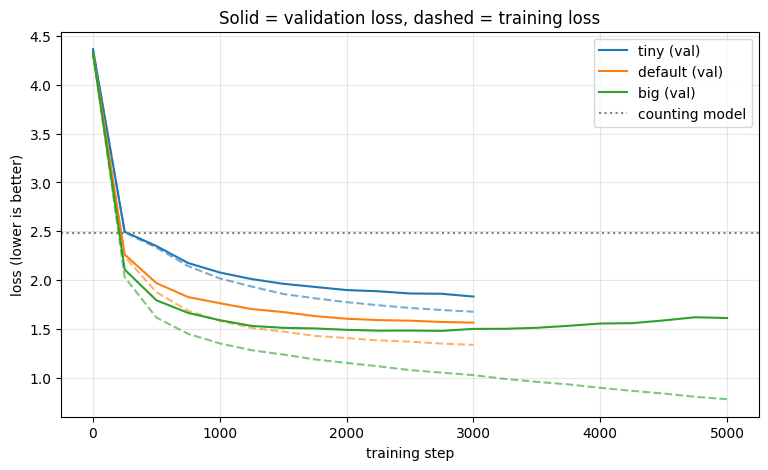

ROMEO:
My lord, my lord, and a man is not me?

JULIET:
Then in a world may in the eath of the
methought of the common lips.

Nurse:
No more, no more: what said me than he should be?

DUKE OF AUMERLE:
Shall I not, but, my lord?

LADY ANNE:
My lord.

KING RICHARD III:
Norfolk, whiles I come to call the Padua love.

Lords:
The cause of Marcius shall clear the months in his prince
And so weeping hereto a beastly gentleman
And noble in world age to worse her death
At one that Camillo shall win the last.

B


In [13]:
summary()
plot("tiny", "default", "big")
write("big", prompt="ROMEO:", temperature=0.8)

### B. Cause overfitting, then fix it

Train a fairly big model on only **20,000 characters** of text, with no dropout. Watch the numbers: train loss keeps falling, but val loss stops falling and then **rises**. The model is memorising its little bit of text instead of learning how English works.

In [14]:
train("overfit", train_chars=20_000, dropout=0.0, n_layer=6, n_embd=256)

Run 'overfit': 4,805,185 parameters, 20,000 training characters, 3000 steps
  step  train loss  val loss    time
     0       4.324     4.332      3s
   250       0.965     2.909     33s
   500       0.130     4.908     61s
   750       0.101     5.304     90s
  1000       0.091     5.578    119s
  1250       0.083     5.652    148s
  1500       0.079     5.875    177s
  1750       0.078     5.959    206s
  2000       0.076     6.016    234s
  2250       0.073     6.109    263s
  2500       0.071     6.223    292s
  2750       0.070     6.237    321s
  3000       0.071     6.320    350s

Best val loss: 2.909   (counting model: 2.482)


Now try two fixes. Which helps more: **dropout**, or **more data**?

In [15]:
train("overfit_dropout", train_chars=20_000, dropout=0.4, n_layer=6, n_embd=256)

Run 'overfit_dropout': 4,805,185 parameters, 20,000 training characters, 3000 steps
  step  train loss  val loss    time
     0       4.324     4.332      3s
   250       1.624     2.455     33s
   500       0.835     2.837     63s
   750       0.260     3.670     93s
  1000       0.121     4.501    122s
  1250       0.093     5.075    152s
  1500       0.086     5.442    182s
  1750       0.079     5.717    212s
  2000       0.076     5.891    241s
  2250       0.075     5.950    271s
  2500       0.073     6.126    301s
  2750       0.071     6.279    331s
  3000       0.070     6.366    360s

Best val loss: 2.455   (counting model: 2.482)


In [16]:
train("overfit_moredata", dropout=0.0, n_layer=6, n_embd=256)

Run 'overfit_moredata': 4,805,185 parameters, 1,003,854 training characters, 3000 steps
  step  train loss  val loss    time
     0       4.331     4.332      3s
   250       1.853     1.961     32s
   500       1.553     1.731     61s
   750       1.418     1.640     90s
  1000       1.340     1.578    119s
  1250       1.280     1.550    148s
  1500       1.240     1.552    177s
  1750       1.192     1.571    206s
  2000       1.151     1.581    235s
  2250       1.122     1.586    263s
  2500       1.079     1.598    293s
  2750       1.037     1.638    321s
  3000       0.994     1.673    350s

Best val loss: 1.550   (counting model: 2.482)


run                   parameters  best val loss
default                  826,433          1.566
tiny                     116,673          1.832
big                   10,795,841          1.481
overfit                4,805,185          2.909
overfit_dropout        4,805,185          2.455
overfit_moredata       4,805,185          1.550


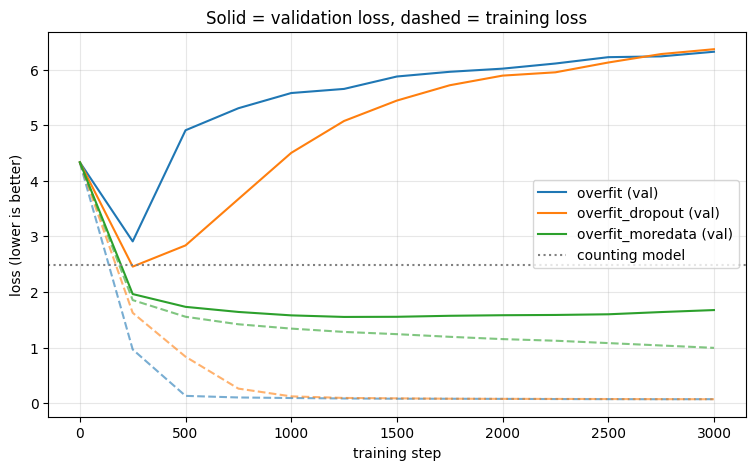

In [17]:
summary()
plot("overfit", "overfit_dropout", "overfit_moredata")

### C. How far back does it need to look?
This model can only see the last **8** characters, compared with 128 for `default`.

In [18]:
train("context8", block_size=8)

Run 'context8': 811,073 parameters, 1,003,854 training characters, 3000 steps
  step  train loss  val loss    time
     0       4.355     4.350      0s
   250       2.196     2.238      4s
   500       2.087     2.144      8s
   750       2.004     2.076     12s
  1000       1.965     2.038     16s
  1250       1.911     2.023     20s
  1500       1.863     1.980     24s
  1750       1.871     1.988     28s
  2000       1.834     1.979     32s
  2250       1.814     1.974     36s
  2500       1.817     1.941     40s
  2750       1.797     1.935     44s
  3000       1.803     1.926     48s

Best val loss: 1.926   (counting model: 2.482)


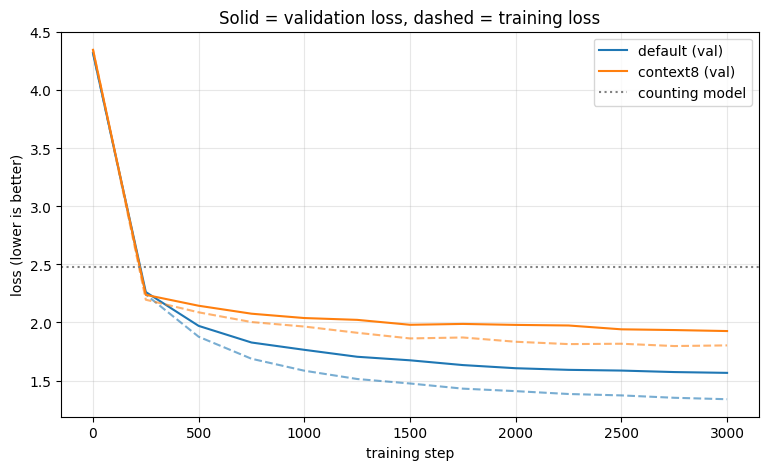

ROMEO:
I cannot constor:
Here, not your fame, quorrance the rreath, that king.

KING RICHARD IGl storr her warrel to must the not leck out
way love me of the stold, I tall the bina do farewell conterns,
The king? my Carrumpery to the is the more to marry again this mane there to julies in a
speep to down but is the father in a cannishy by revenge, coments the colding sut amble be him:
I would, let is rest shall man greath soend harge my delse unlius his pilet.

Clown:
Herefore you a more landst if the


In [19]:
plot("default", "context8")
write("context8", prompt="ROMEO:", temperature=0.8)

### D. Temperature
Low temperature is safe but repetitive; high temperature is creative but full of mistakes. This is the same setting you fixed at 0 in your maths eval.

In [20]:
for t in [0.5, 1.0, 1.5]:
    print(f"========== temperature {t} ==========")
    write("default", prompt="JULIET:", temperature=t, length=300)
    print()

========== temperature 0.5 ==========
JULIET:
Will the Signior Marcius way to say the world
That cure to my man that son's my brother better than my
The brother to be stands the father than leave:
And the cannot of the nest, and see his poison;
And thou art thou wast in my sailor.

ROMEO:
I will be thee, my lord?

AUTOLYCUS:
I have not the bea

========== temperature 1.0 ==========
JULIET:
I would them! While you not?

LADY ANNE:
That's no makes them make it.

POLIXENES:
You, more untime, consent to it. For thee and stay incoud
known be weakings again.

YORK:
I speak to him: our son holy is weakning glory old place;
That from where is it--to great ourself.

RICHARD:
Not make they hav

========== temperature 1.5 ==========
JULIET:
wot.

VOLUMNIA:
You watter six would bear
Wounds, his fire. Beleralo, War? lovethomp?

COPSON:
Ay, sion waron.

Father:
O slowy,, one thing, Montague:
By; both crossions, Hastinces come.--it n Join
Of alike Mesdim!-pute the enter-caidi, chambercher
Well ishall

## Save your results

Colab deletes everything when the session ends. Run this box to download your loss logs and writing samples as a zip file.

In [21]:
import json, zipfile
with zipfile.ZipFile("tiny_gpt_results.zip", "w") as z:
    for name, r in runs.items():
        z.writestr(f"{name}/log.csv", "step,train_loss,val_loss\n" +
                   "\n".join(f"{s},{t:.4f},{v:.4f}" for s, t, v in r["log"]))
        z.writestr(f"{name}/samples.txt", "\n".join(f"===== step {s} (val {v:.3f}) =====\n{t}\n" for s, v, t in r["samples"]))
    z.writestr("summary.json", json.dumps({n: dict(params=r["params"], best_val=r["best_val"]) for n, r in runs.items()}, indent=2))
try:
    from google.colab import files
    files.download("tiny_gpt_results.zip")
except ImportError:
    print("Saved tiny_gpt_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Findings

Double-click this box to write what you found, as you did for the maths eval:

- **Size:**
- **Overfitting:**
- **Context length:**
- **Temperature:**